# RM5 · Fourier pairs, sampling, aliasing and windowing

**Part:** Math refresher · **Reading time:** ~30 min · **Pass 1 overview:** [From signal to image](../pass1_big_picture/P1.3_From_Signal_to_Image.ipynb) · **Refreshers you may want:** [RM3 Continuous FT and DFT](RM3_Continuous_FT_and_DFT.ipynb), [RM4 Fourier properties](RM4_Fourier_Properties.ipynb)

A dozen Fourier pairs and two facts about sampling explain most of what you will ever see in an MRI image:
why the field of view is $1/\Delta k$ and objects outside it **wrap around**, why the pixel size is $1/(2k_{max})$, why sharp edges **ring**,
and why scanners offer "filters" that trade sharpness for less ringing. This notebook collects the pairs (with numerical checks),
then derives these imaging facts from them.

## Learning goals

1. Know the pairs rect ↔ sinc, triangle ↔ sinc², Gaussian ↔ Gaussian, delta ↔ constant, comb ↔ comb, disk ↔ jinc, including widths and heights.
2. Explain sampling as multiplication by a comb, and derive replication and aliasing ($FOV=1/\Delta k$).
3. Explain finite sampling as multiplication by a rect, and derive sinc blurring, the resolution $1/(2k_{max})$ and Gibbs ringing.
4. Compare rectangular, Hann and Hamming windows: main-lobe width vs side-lobe level.

## Symbols used in this notebook

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $x$, $k$ | position, spatial frequency | m, m⁻¹ | |
| $f, F$ | a function and its Fourier transform | | MRI convention $e^{-i2\pi kx}$ |
| $\mathrm{rect}(x)$ | unit box: 1 for $\lvert x\rvert<1/2$, 1/2 at $\lvert x\rvert=1/2$, else 0 | – | `mt.rect` |
| $\mathrm{sinc}(x)=\sin(\pi x)/(\pi x)$ | normalized sinc | – | `np.sinc`, `mt.sinc` |
| $\mathrm{tri}(x)$ | unit triangle $\max(1-\lvert x\rvert,0)$ | – | |
| $\delta(x)$ | Dirac delta (unit-area spike) | m⁻¹ | not the resolution $\delta$! |
| $\mathrm{III}(x)=\sum_n\delta(x-n)$ | Dirac comb (sampling function, "sha") | – | |
| $\mathrm{jinc}(x)=J_1(\pi x)/(\pi x)$ | circular analogue of sinc ($J_1$: Bessel function of the first kind) | – | `mt.jinc`, $=1/2$ at 0 |
| $\rho=\sqrt{k_x^2+k_y^2}$ | radial spatial frequency | m⁻¹ | |
| $W$, $a$, $R_d$ | rect width, Gaussian width, disk radius | m | |
| $\Delta k$, $FOV=1/\Delta k$ | k-space sample spacing, field of view | m⁻¹, m | 4 m⁻¹ ↔ 25 cm |
| $k_{max}$, $\delta=1/(2k_{max})$ | largest sampled k, nominal resolution (pixel size) | m⁻¹, m | 500 m⁻¹ ↔ 1 mm |
| $\Delta x$ | pixel spacing (= $\delta$ for Cartesian sampling) | m | |
| $N$ | number of samples | – | |
| $m(x)$, $M(k)$ | object and its k-space (here $M$ = k-space data, not magnetization) | a.u. | |
| $w(k)$ | k-space window (apodization) | – | Hann, Hamming |
| $h(x)$ | point spread function (PSF) | m⁻¹ | |
| FWHM | full width at half maximum | m | |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

N, dx = 512, 0.5e-3                          # 0.5 mm samples, 25.6 cm
x = (np.arange(N) - N // 2) * dx             # [m]
dk = 1 / (N * dx)
k = (np.arange(N) - N // 2) * dk             # [1/m]
FT = lambda f: dx * np.sqrt(N) * mt.fftc(f)      # numerical continuous FT (RM3)
IFT = lambda F: dk * np.sqrt(N) * mt.ifftc(F)

## 1. The pairs (MRI convention, $F(k)=\int f(x)e^{-i2\pi kx}dx$)

| $f(x)$ | $F(k)$ | remark |
|---|---|---|
| $\delta(x)$ | $1$ | a point contains all frequencies equally |
| $1$ | $\delta(k)$ | a constant has only $k=0$ |
| $\delta(x-x_0)$ | $e^{-i2\pi kx_0}$ | shift theorem |
| $e^{+i2\pi k_0x}$ | $\delta(k-k_0)$ | a single complex wave = a single k-space point |
| $\mathrm{rect}(x/W)$ | $W\,\mathrm{sinc}(Wk)$ | zeros at $k=n/W$; height = area $W$ |
| $\mathrm{sinc}(x)$ | $\mathrm{rect}(k)$ | duality |
| $\mathrm{tri}(x/W)$ | $W\,\mathrm{sinc}^2(Wk)$ | tri = rect ∗ rect, so FT = sinc·sinc |
| $e^{-\pi x^2/a^2}$ | $a\,e^{-\pi a^2k^2}$ | the Gaussian is its own transform |
| $e^{-t/T}$ for $t\ge0$ | $1/(1/T+i2\pi f)$ | FID ↔ Lorentzian line ([RM3](RM3_Continuous_FT_and_DFT.ipynb)) |
| $\sum_n\delta(x-n\Delta)$ | $\frac{1}{\Delta}\sum_m\delta(k-m/\Delta)$ | comb of spacing $\Delta$ ↔ comb of spacing $1/\Delta$ |
| disk of radius $R_d$ (2D) | $2\pi R_d^2\,\mathrm{jinc}(2R_d\rho)$ | circular sinc; first zero at $\rho=0.61/R_d$ |

Properties of the **Dirac delta** you will use: $\int\delta(x)dx=1$; $\delta(x)=0$ for $x\neq0$; **sifting** $\int f(x)\delta(x-x_0)dx=f(x_0)$; $f(x)\delta(x-x_0)=f(x_0)\delta(x-x_0)$;
$f*\delta=f$; $\delta(ax)=\delta(x)/|a|$. The delta is not an ordinary function (a "distribution"): think of it as the limit of ever narrower unit-area rects or Gaussians.
On a grid, it is one sample of height $1/\Delta x$.

> **⚠️ Common confusion:** "jinc" has several definitions in the literature (with or without factors 2 and $\pi$). `mt.jinc` follows Larson's code, $J_1(\pi x)/(\pi x)$, which equals 1/2 at 0; the pair above is written for that definition.

rect(x/W)                  max|num - analytic| / max|analytic| = 7.8e-03
tri(x/W)                   max|num - analytic| / max|analytic| = 9.1e-05
Gaussian, a = W/2          max|num - analytic| / max|analytic| = 1.7e-16
sinc(x/Ws)/Ws, Ws = 5 mm   max|num - analytic| / max|analytic| = 1.3e-01
delta (1 sample of 1/dx)   max|num - analytic| / max|analytic| = 0.0e+00


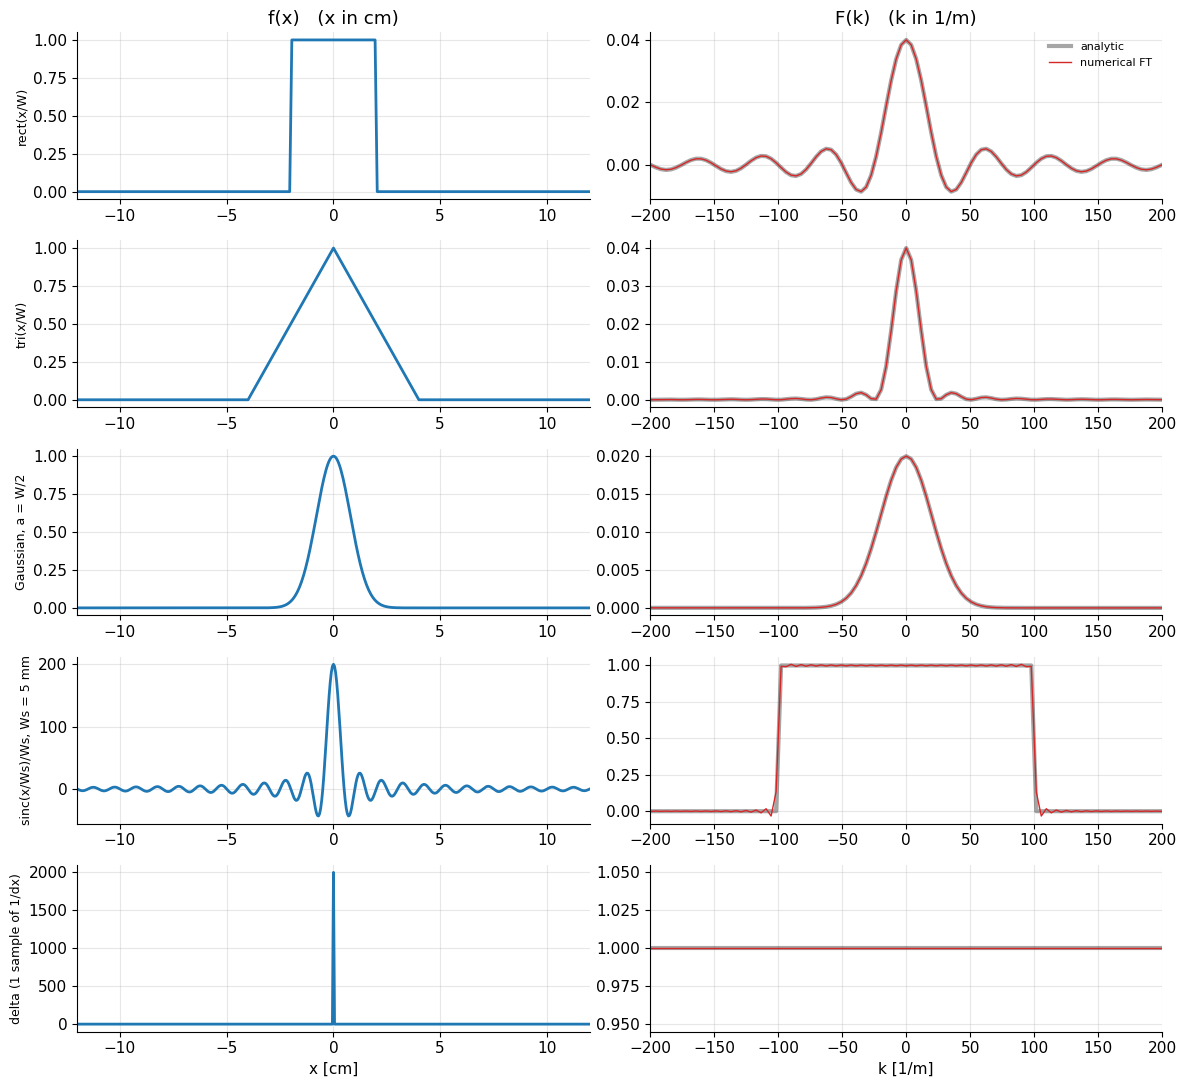

In [2]:
W = 0.04                                                   # 4 cm
pairs = [
    ("rect(x/W)",        mt.rect(x / W),                         W * np.sinc(W * k)),
    ("tri(x/W)",         np.maximum(1 - np.abs(x / W), 0),       W * np.sinc(W * k) ** 2),
    ("Gaussian, a = W/2", np.exp(-np.pi * (x / (W / 2)) ** 2),   (W / 2) * np.exp(-np.pi * (W / 2 * k) ** 2)),
    ("sinc(x/Ws)/Ws, Ws = 5 mm", np.sinc(x / 0.005) / 0.005,     mt.rect(k * 0.005)),
    ("delta (1 sample of 1/dx)", (np.abs(x) < dx / 2) / dx,      np.ones(N)),
]
fig, ax = plt.subplots(len(pairs), 2, figsize=(12, 2.2 * len(pairs)))
for i, (name, f, F_true) in enumerate(pairs):
    F_num = FT(f)
    ax[i, 0].plot(x * 100, f, lw=2); ax[i, 0].set_xlim(-12, 12); ax[i, 0].set_ylabel(name, fontsize=9)
    ax[i, 1].plot(k, F_true, "k", lw=3, alpha=0.35, label="analytic")
    ax[i, 1].plot(k, F_num.real, "C3", lw=1, label="numerical FT")
    ax[i, 1].set_xlim(-200, 200)
    print(f"{name:26s} max|num - analytic| / max|analytic| = {np.max(np.abs(F_num - F_true)) / np.max(np.abs(F_true)):.1e}")
ax[0, 0].set_title("f(x)   (x in cm)"); ax[0, 1].set_title("F(k)   (k in 1/m)"); ax[0, 1].legend(fontsize=8)
ax[-1, 0].set_xlabel("x [cm]"); ax[-1, 1].set_xlabel("k [1/m]")
plt.tight_layout(); plt.show()

All pairs check out. The rect has a sub-percent error because its sharp edge cannot be sampled exactly; the sinc row shows ripples at the edges of its rect because the sinc's slowly decaying tails are cut off at the edge of the 25.6 cm grid — that is Gibbs ringing, explained in section 3. Note the widths: a 4 cm rect has sinc zeros every 25 m⁻¹, a sinc with 5 mm zero spacing becomes a rect 200 m⁻¹ wide.

### Disk ↔ jinc (2D)

Images are 2D, and round objects (a vessel cross-section, a round k-space sampling region) give the circular analogue of the sinc. Its first zero is at $\rho=1.22/(2R_d)$ — the
same factor 1.22 as the Airy disk in optics.

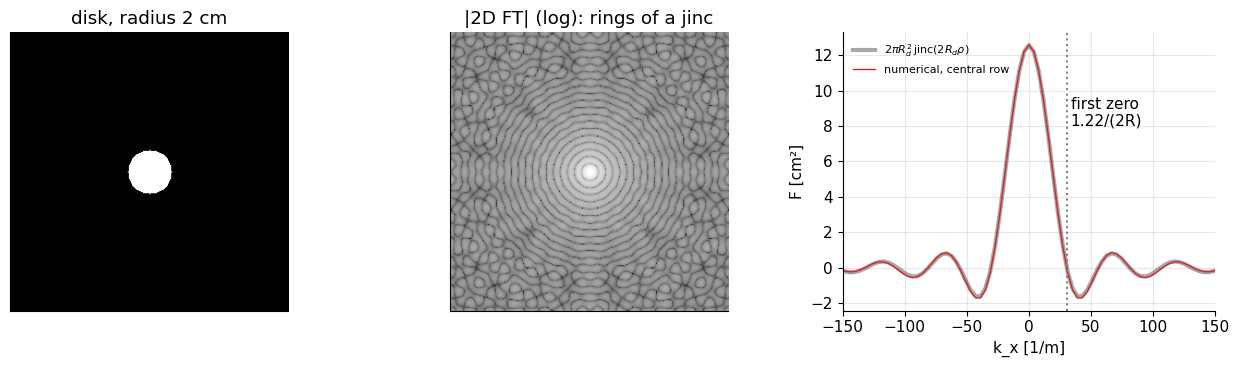

In [3]:
N2, dx2 = 256, 1e-3                                   # 1 mm pixels, 25.6 cm FOV
xx = (np.arange(N2) - N2 // 2) * dx2
X, Y = np.meshgrid(xx, xx)
Rd = 0.02                                             # disk radius 2 cm
disk = (np.hypot(X, Y) <= Rd).astype(float)
F2 = dx2**2 * N2 * mt.fft2c(disk)                     # continuous 2D FT: dx^2 * sqrt(N^2) * fft2c
kk = (np.arange(N2) - N2 // 2) / (N2 * dx2)
F_jinc = 2 * np.pi * Rd**2 * mt.jinc(2 * Rd * np.abs(kk))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
mt.show_image(disk, ax=ax[0], title="disk, radius 2 cm")
mt.show_kspace(F2, ax=ax[1], title="|2D FT| (log): rings of a jinc")
ax[2].plot(kk, F_jinc * 1e4, "k", lw=3, alpha=0.35, label=r"$2\pi R_d^2\,\mathrm{jinc}(2R_d\rho)$")
ax[2].plot(kk, F2[N2 // 2].real * 1e4, "C3", lw=1, label="numerical, central row")
ax[2].axvline(1.22 / (2 * Rd), color="0.5", ls=":"); ax[2].text(1.22 / (2 * Rd) + 3, 8, "first zero\n1.22/(2R)")
ax[2].set_xlim(-150, 150); ax[2].set_xlabel("k_x [1/m]"); ax[2].set_ylabel("F [cm²]"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

The numerical transform of the pixelated disk matches the analytic jinc, with its first zero at 30.5 m⁻¹; in 2D it forms concentric rings.

## 2. Sampling = multiplication by a comb → replication → aliasing

MRI measures k-space at discrete points spaced $\Delta k$. Mathematically the sampled data are

$$M_s(k)=M(k)\cdot\sum_n\delta(k-n\Delta k).$$

In words: the true k-space times a comb of spikes. Where: $M(k)$ = k-space of the object $m(x)$ [a.u.], $\Delta k$ = sample spacing [m⁻¹].

By the convolution theorem and the comb ↔ comb pair, the image we reconstruct is

$$m_s(x)=m(x)*\frac{1}{\Delta k}\sum_n\delta\!\left(x-\frac{n}{\Delta k}\right)=\frac{1}{\Delta k}\sum_n m\!\left(x-n\,FOV\right),\qquad FOV=\frac{1}{\Delta k}.$$

In words: sampling k-space makes the image **periodic**: copies of the object repeat every $FOV=1/\Delta k$. If the object is smaller than the FOV the copies do not overlap and one period is the
exact object. If it is larger, the copies overlap: parts outside the FOV **fold back** in from the other side — **aliasing** (wrap-around). Where: $n$ = integer copy index.

This is the sampling theorem you know from time signals (sample faster than twice the highest frequency), with the roles of the domains swapped: here the "band limit" is the object size.

The demo samples the *analytic* k-space of a 1D "body" (a 20 cm torso with a 3 cm arm next to it) at two different spacings.

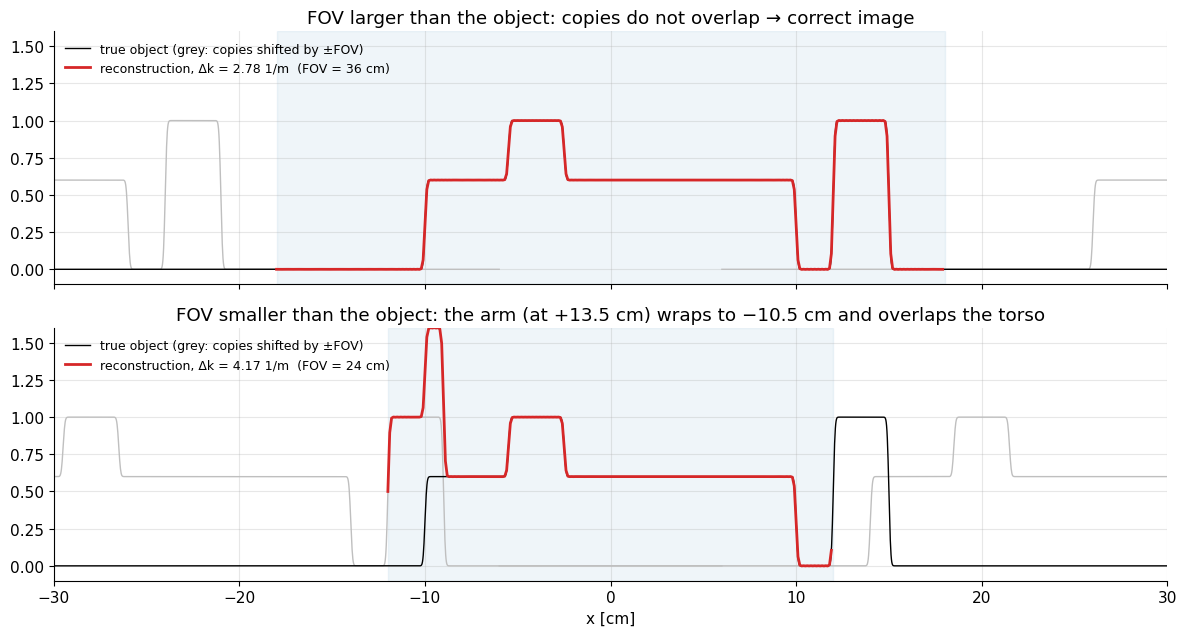

In [4]:
# 1D object made of "soft" rects (edges blurred by a 2 mm Gaussian) -> analytic FT known exactly
parts = [(0.0, 0.20, 0.6), (0.135, 0.03, 1.0), (-0.04, 0.03, 0.4)]   # (centre [m], width [m], amplitude)
sig = 2e-3
def obj(xv):
    from scipy.special import erf
    s = sig / np.sqrt(2 * np.pi)          # Gaussian exp(-pi x^2/sig^2) has std sig/sqrt(2 pi)
    return sum(A * 0.5 * (erf((xv - c + w / 2) / (np.sqrt(2) * s)) - erf((xv - c - w / 2) / (np.sqrt(2) * s))) for c, w, A in parts)
def obj_FT(kv):
    return sum(A * w * np.sinc(w * kv) * np.exp(-1j * 2 * np.pi * kv * c) for c, w, A in parts) * np.exp(-np.pi * (sig * kv) ** 2)

def recon(FOV, dxr=1e-3):
    """Sample the analytic k-space with dk = 1/FOV out to k_max = 1/(2 dxr), reconstruct by inverse FFT."""
    Nr = int(round(FOV / dxr))
    kr = (np.arange(Nr) - Nr // 2) / FOV
    xr = (np.arange(Nr) - Nr // 2) * dxr
    return xr, (1 / FOV) * np.sqrt(Nr) * mt.ifftc(obj_FT(kr))

xfine = np.linspace(-0.3, 0.3, 3000)
fig, ax = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
for a_, FOV in zip(ax, [0.36, 0.24]):
    xr, mr = recon(FOV)
    for n in [-1, 1]:                                   # neighbouring copies predicted by the theory
        a_.plot((xfine + n * FOV) * 100, obj(xfine), color="0.75", lw=1)
    a_.plot(xfine * 100, obj(xfine), "k", lw=1, label="true object (grey: copies shifted by ±FOV)")
    a_.plot(xr * 100, mr.real, "C3", lw=2, label=f"reconstruction, Δk = {1/FOV:.2f} 1/m  (FOV = {FOV*100:.0f} cm)")
    a_.axvspan(-FOV / 2 * 100, FOV / 2 * 100, color="C0", alpha=0.07)
    a_.legend(fontsize=9, loc="upper left"); a_.set_ylim(-0.1, 1.6)
ax[0].set_title("FOV larger than the object: copies do not overlap → correct image")
ax[1].set_title("FOV smaller than the object: the arm (at +13.5 cm) wraps to −10.5 cm and overlaps the torso")
ax[1].set_xlabel("x [cm]"); ax[1].set_xlim(-30, 30); plt.tight_layout(); plt.show()

With a 36 cm FOV the reconstruction (red) equals the object; with a 24 cm FOV the arm sticking out past +12 cm reappears at the left edge, exactly where the shifted copy (grey) predicts.

> **🔧 Engineering reality:** in the **readout** (frequency-encoding) direction aliasing is prevented almost for free: the receiver samples faster than needed ("2× oversampling")
> and applies an anti-aliasing low-pass filter before decimation, so signal from outside the FOV is filtered out. In the **phase-encoding** directions each extra k-space line costs one TR,
> so wrap-around is a real trade-off against scan time ("phase oversampling", "no phase wrap" options). See [G1 FOV and resolution](../pass2_deep_dive/G1_FOV_and_Resolution.ipynb) and [I2 Artifacts](../pass2_deep_dive/I2_Artifacts.ipynb).
> Deliberate undersampling (skipping lines) creates *controlled* aliasing that parallel imaging then unfolds ([H3 Accelerated imaging](../pass2_deep_dive/H3_Accelerated_Imaging_Methods.ipynb)).

## 3. Finite extent = multiplication by a rect → sinc blurring and Gibbs ringing

We can only sample out to $\pm k_{max}$. That multiplies k-space by a rect of width $2k_{max}$:

$$\hat M(k)=M(k)\,\mathrm{rect}\!\left(\frac{k}{2k_{max}}\right)\quad\Longrightarrow\quad\hat m(x)=m(x)*\underbrace{2k_{max}\,\mathrm{sinc}(2k_{max}x)}_{\text{PSF }h(x)}.$$

In words: the image is the object blurred by a sinc whose main lobe has its first zeros at $x=\pm1/(2k_{max})$. Where: $k_{max}$ = largest sampled spatial frequency [m⁻¹], $\hat m$ = reconstructed image.

Consequences:

- **Resolution.** Two points closer than about $1/(2k_{max})$ merge. With $N$ samples spaced $\Delta k$, $2k_{max}=N\Delta k$ and $\delta=1/(2k_{max})=FOV/N$ = the pixel size. The PSF's FWHM is $\approx1.21\,\delta$.
- **Gibbs ringing.** The sinc has negative and positive side lobes, so a sharp edge is reproduced with ripples. The first overshoot is ≈ 9 % of the edge height and does **not** shrink when you sample further out —
  the ripples only get narrower and closer to the edge. In MRI this is the "truncation artifact", often seen as parallel lines near the skull or in the spinal cord.

The demo is a port of the truncation example in the original "MRI Math Concepts" chapter: the k-space of a sharp 4 cm rect, truncated at different $k_{max}$.

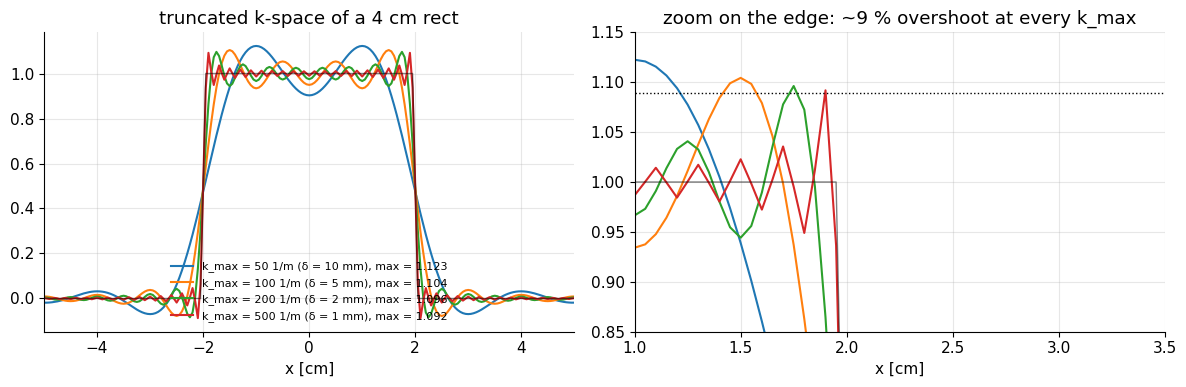

In [5]:
W = 0.04
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for kmax in [50, 100, 200, 500]:                       # [1/m]
    Fk = W * np.sinc(W * k) * (np.abs(k) <= kmax)      # analytic k-space of rect(x/W), truncated
    m_hat = IFT(Fk).real
    ax[0].plot(x * 100, m_hat, label=f"k_max = {kmax} 1/m (δ = {1/(2*kmax)*1000:.0f} mm), max = {m_hat.max():.3f}")
    ax[1].plot(x * 100, m_hat, label=f"k_max = {kmax}")
for a_ in ax:
    a_.plot(x * 100, mt.rect(x / W), "k", lw=1, alpha=0.5)
ax[0].set_xlim(-5, 5); ax[0].set_xlabel("x [cm]"); ax[0].legend(fontsize=8, loc="lower center"); ax[0].set_title("truncated k-space of a 4 cm rect")
ax[1].set_xlim(1.0, 3.5); ax[1].set_ylim(0.85, 1.15); ax[1].set_xlabel("x [cm]"); ax[1].set_title("zoom on the edge: ~9 % overshoot at every k_max")
ax[1].axhline(1.0895, color="k", ls=":", lw=1)
plt.tight_layout(); plt.show()

Larger $k_{max}$ sharpens the edge and squeezes the ripples towards it, but the first overshoot stays at ≈ 1.09 (dotted line) — the Gibbs phenomenon.

## 4. Windowing (apodization): trading resolution for less ringing

Instead of cutting k-space off abruptly, we can multiply it by a smooth **window** $w(k)$ that tapers to (nearly) zero at $\pm k_{max}$. The PSF becomes the inverse FT of the window. Common choices, for $|k|\le k_{max}$:

$$w_{Hann}(k)=\tfrac12\big(1+\cos(\pi k/k_{max})\big),\qquad w_{Hamming}(k)=0.54+0.46\cos(\pi k/k_{max}).$$

In words: both are raised cosines; Hann goes all the way to 0 at the edge, Hamming to 0.08 (its coefficients are chosen to cancel the first side lobe). Where: $k_{max}$ [m⁻¹].

The smoother the window, the lower the side lobes (less ringing) but the wider the main lobe (more blur) — you cannot win both, by the scaling theorem.

rect (no window) : FWHM = 2.44 mm = 1.22 δ,  highest side lobe = -13.3 dB
Hann             : FWHM = 4.00 mm = 2.00 δ,  highest side lobe = -31.5 dB


Hamming          : FWHM = 3.64 mm = 1.82 δ,  highest side lobe = -42.7 dB


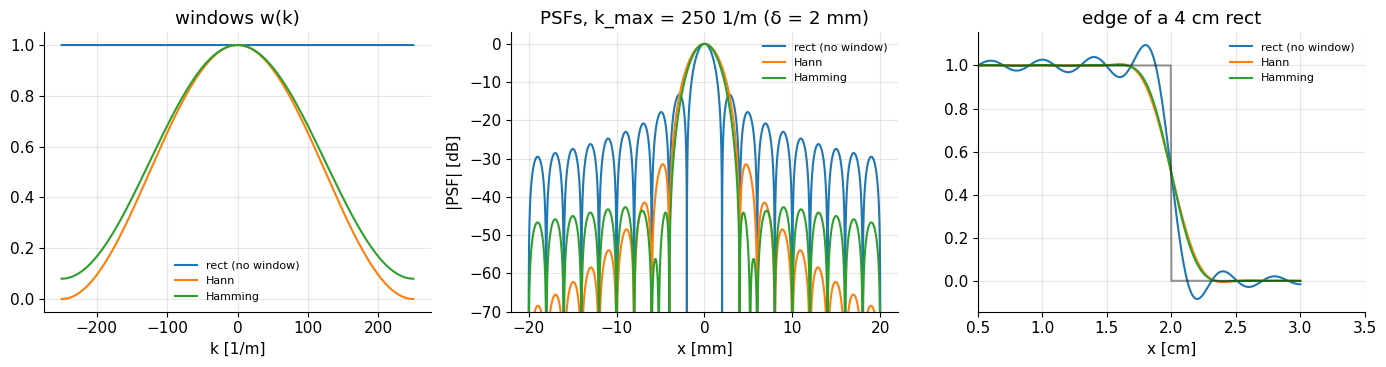

In [6]:
kmax = 250.0                                           # [1/m]  -> delta = 2 mm
kd = np.linspace(-kmax, kmax, 4001)                    # dense k grid for an accurate PSF
xd = np.linspace(-0.02, 0.02, 2001)                    # [m]
windows = {"rect (no window)": np.ones_like(kd),
           "Hann": 0.5 * (1 + np.cos(np.pi * kd / kmax)),
           "Hamming": 0.54 + 0.46 * np.cos(np.pi * kd / kmax)}
kern = np.exp(1j * 2 * np.pi * np.outer(xd, kd)) * (kd[1] - kd[0])

def fwhm_and_sidelobe(h):
    h = h / h.max()
    c = len(h) // 2
    above = np.where(h[c:] < 0.5)[0][0]
    fwhm = 2 * (xd[c + above] - xd[c])                  # coarse but fine for 2001 points
    d = np.diff(np.abs(h[c:]))
    first_min = np.where(d > 0)[0][0]                   # first null of |h| right of the centre
    return fwhm, np.abs(h[c + first_min:]).max()

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
x_edge = np.linspace(-0.01, 0.03, 801)
for name, w in windows.items():
    h = (kern @ w).real
    fw, sl = fwhm_and_sidelobe(h)
    ax[0].plot(kd, w, label=name)
    print(f"{name:17s}: FWHM = {fw*1000:.2f} mm = {fw*2*kmax:.2f} δ,  highest side lobe = {20*np.log10(sl):5.1f} dB")
    ax[1].plot(xd * 1000, 20 * np.log10(np.abs(h) / h.max() + 1e-6), label=name)
    # edge response: image of a rect of width 4 cm, windowed k-space
    Fk = W * np.sinc(W * kd) * w
    m_edge = (np.exp(1j * 2 * np.pi * np.outer(x_edge, kd)) @ Fk).real * (kd[1] - kd[0])
    ax[2].plot(x_edge * 100, m_edge, label=name)
ax[0].set_xlabel("k [1/m]"); ax[0].set_title("windows w(k)"); ax[0].legend(fontsize=8)
ax[1].set_ylim(-70, 3); ax[1].set_xlabel("x [mm]"); ax[1].set_ylabel("|PSF| [dB]"); ax[1].set_title(f"PSFs, k_max = {kmax:.0f} 1/m (δ = 2 mm)"); ax[1].legend(fontsize=8, loc="upper right")
ax[2].plot(x_edge * 100, mt.rect(x_edge / W), "k", alpha=0.4); ax[2].set_xlim(0.5, 3.5); ax[2].set_xlabel("x [cm]"); ax[2].set_title("edge of a 4 cm rect"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

The rect window gives the narrowest PSF but −13 dB side lobes (visible ringing at the edge); Hann and Hamming push the side lobes down to about −31 and −43 dB and remove the ringing, at the cost of a 50–65 % wider PSF (blurrier edge).

> **🔧 Engineering reality:** scanner reconstruction menus offer such filters under names like "raw filter", "k-space filter" or "apodization" (often Hamming/Hann/Fermi variants).
> The same idea is used for **RF pulses**: a sinc pulse must be truncated in time, so it is multiplied by a Hamming or Hann window to get a slice profile with small side lobes
> ([E3 RF pulse design](../pass2_deep_dive/E3_RF_Pulse_Design.ipynb)).

## Where this shows up in MRI

| Idea | Where it is used |
|---|---|
| rect ↔ sinc for RF pulses and slice profiles | [E1 RF pulses](../pass2_deep_dive/E1_RF_Pulses.ipynb), [E2 Slice selection](../pass2_deep_dive/E2_Slice_Selection.ipynb), [E3 RF pulse design](../pass2_deep_dive/E3_RF_Pulse_Design.ipynb) |
| comb sampling, $FOV=1/\Delta k$, wrap-around | [G1 FOV and resolution](../pass2_deep_dive/G1_FOV_and_Resolution.ipynb), [I2 Artifacts](../pass2_deep_dive/I2_Artifacts.ipynb), [H3 Accelerated imaging](../pass2_deep_dive/H3_Accelerated_Imaging_Methods.ipynb) |
| finite extent → sinc PSF, $\delta=1/(2k_{max})$, Gibbs ringing | [G1 FOV and resolution](../pass2_deep_dive/G1_FOV_and_Resolution.ipynb), [G3 Cartesian image characteristics](../pass2_deep_dive/G3_Cartesian_Image_Characteristics.ipynb), [I1 PSF analysis](../pass2_deep_dive/I1_Point_Spread_Function_Analysis.ipynb) |
| windowing / filters | [G3 Cartesian image characteristics](../pass2_deep_dive/G3_Cartesian_Image_Characteristics.ipynb), [F3 Image reconstruction](../pass2_deep_dive/F3_Image_Reconstruction.ipynb) |
| disk ↔ jinc | [I1 PSF analysis](../pass2_deep_dive/I1_Point_Spread_Function_Analysis.ipynb), [H1 Volumetric imaging](../pass2_deep_dive/H1_Volumetric_Imaging.ipynb) (elliptical k-space sampling) |
| Lorentzian ↔ exponential | [A3 In vivo spin physics](../pass2_deep_dive/A3_In_Vivo_Spin_Physics.ipynb), [RM2](RM2_Complex_Numbers_and_Rotations.ipynb) ($T_2'$) |

Compact formula sheet: [MRI math concepts](../reference/MRI_Math_Concepts.ipynb).

## Key takeaways

- rect$(x/W)$ ↔ $W\,\mathrm{sinc}(Wk)$, tri ↔ sinc², Gaussian ↔ Gaussian, δ ↔ 1, comb($\Delta$) ↔ comb($1/\Delta$), disk ↔ jinc (first zero at $1.22/(2R_d)$).
- Sampling k-space with spacing $\Delta k$ replicates the image every $FOV=1/\Delta k$; an object larger than the FOV wraps around (aliasing).
- Sampling only out to $k_{max}$ convolves the image with a sinc: resolution $\delta=1/(2k_{max})$ (FWHM ≈ 1.21 δ).
- Gibbs ringing: ≈ 9 % overshoot at sharp edges regardless of $k_{max}$; only the ripple width shrinks.
- Windows (Hann, Hamming) suppress side lobes/ringing but widen the PSF: sharpness vs ringing is a trade-off, not a free lunch.

## Check your understanding

1. You want a 22 cm FOV with 0.8 mm pixels. What $\Delta k$, $k_{max}$ and number of samples $N$ do you need?
<details><summary>Answer</summary>

$\Delta k=1/0.22\approx4.55$ m⁻¹; $k_{max}=1/(2\cdot0.8\text{ mm})=625$ m⁻¹; $N=FOV/\delta=275$ (in practice rounded to e.g. 288 or 320).

</details>

2. A patient's shoulders extend 4 cm beyond the phase-encode FOV on the right. Where do they appear in the image?
<details><summary>Answer</summary>

Shifted by one FOV: they appear in the leftmost 4 cm of the image, superimposed on whatever is there (wrap-around).

</details>

3. Doubling the number of k-space samples while keeping $\Delta k$ fixed: what happens to the Gibbs overshoot and to the ringing pattern?
<details><summary>Answer</summary>

$k_{max}$ doubles, so the PSF becomes twice as narrow; the ripples are half as wide and closer to the edge, but the first overshoot stays at ≈ 9 %.

</details>

4. Why does a Hamming window reduce ringing, and what is the price?
<details><summary>Answer</summary>

It tapers k-space smoothly, so its transform (the PSF) has much lower side lobes (≈ −43 dB vs −13 dB). The price is a wider main lobe (≈ 1.5× FWHM): lower effective resolution. (It also slightly lowers noise, since high-k noise is weighted down.)

</details>

5. Why is sampling theory the same for time signals and for k-space, even though the roles of the domains look swapped?
<details><summary>Answer</summary>

The comb ↔ comb pair and the convolution theorem are symmetric. Sampling in either domain with spacing $\Delta$ replicates the other domain with period $1/\Delta$. For time signals the replicated domain is the spectrum (aliasing of frequencies); in MRI we sample k-space, so the image is replicated (aliasing in space).

</details>

---
*New refresher written for this adaptation of P. Larson, "Principles of MRI" (MIT License); section 3 extends the truncation example of the original chapter "MRI Math Concepts". See references below.*
*References: R. N. Bracewell, *The Fourier Transform and Its Applications* (McGraw-Hill);
F. J. Harris, "On the use of windows for harmonic analysis with the discrete Fourier transform", *Proc. IEEE* 66:51–83 (1978);
D. G. Nishimura, *Principles of Magnetic Resonance Imaging*;
M. A. Bernstein, K. F. King, X. J. Zhou, *Handbook of MRI Pulse Sequences* (Elsevier, 2004).*